# Práctica express de regresión lineal
- Autor: Mauricio Montes
- Fecha: 18 jul 2025
---
La idea es aprender a hacer una regresión lineal con el ejercicio original. Así que primero procedemos con la planificación de la limpieza de datos para implementarlo de manera modular en el archivo de python.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Limpieza de datos
Los datos a utilizar son varios registros de vuelo dentro de la India. Los ingenieros que hicieron el dataset se esforzaron en dejarlo lo más limpio que pudieron, y se nota.

In [2]:
df = pd.read_csv('flight-price.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


Solo con la información se puede ver que son un total de 300,153 registros; con 11 columnas. Dado que el objetivo del entrenamiento es predecir el precio de los vuelos, se entiende que la columna `price` es la columna objetivo. Ahora, solo queda ver el contenido del resto de las columnas para determinar si son útiles o no.

In [3]:
df.head(10)

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
5,5,Vistara,UK-945,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.33,1,5955
6,6,Vistara,UK-927,Delhi,Morning,zero,Morning,Mumbai,Economy,2.08,1,6060
7,7,Vistara,UK-951,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.17,1,6060
8,8,GO_FIRST,G8-334,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.17,1,5954
9,9,GO_FIRST,G8-336,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.25,1,5954


Visualizando los datos, hay dos columnas en particular que no parecen ser muy importantes para el entrenamiento: `Unnamed: 0` que parece ser una columna basura de los índices; y `flight` que es la columna de ID's de los vuelos por ponerlo de una forma. Se asume que un vuelo en particular, solo por ser diferente de los demás, no influye en su precio; sino que son el resto de características el que determina su precio.

In [4]:
df.drop(columns=['Unnamed: 0', 'flight'], inplace=True)
df.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


Una cosa que se puede notar es la cantidad de variables categóricas que contiene el vuelo.

In [5]:
df.describe(include='object')

,airline,source_city,departure_time,stops,arrival_time,destination_city,class
count,300153,300153,300153,300153,300153,300153,300153
unique,6,6,6,3,6,6,2
top,Vistara,Delhi,Morning,one,Night,Mumbai,Economy
freq,127859,61343,71146,250863,91538,59097,206666


In [10]:
print(df['airline'].unique())
print(df['source_city'].unique())
print(df['departure_time'].unique())
print(df['stops'].unique())
print(df['arrival_time'].unique())
print(df['destination_city'].unique())
print(df['class'].unique())


['SpiceJet' 'AirAsia' 'Vistara' 'GO_FIRST' 'Indigo' 'Air_India']
['Delhi' 'Mumbai' 'Bangalore' 'Kolkata' 'Hyderabad' 'Chennai']
['Evening' 'Early_Morning' 'Morning' 'Afternoon' 'Night' 'Late_Night']
['zero' 'one' 'two_or_more']
['Night' 'Morning' 'Early_Morning' 'Afternoon' 'Evening' 'Late_Night']
['Mumbai' 'Bangalore' 'Kolkata' 'Hyderabad' 'Chennai' 'Delhi']
['Economy' 'Business']


Estoy seguro de que estas variables categóricas influyen en el precio. Por ejemplo, es claro que un vuelo en clase económica será más barato que un vuelo en clase business; o bien una aerolínea tiene precios más caros que otros. Eso implica que tenemos que codificar esas variables de alguna forma... pero eso será más adelante.

# Transformación de datos
Bueno, con los datos limpios, se puede continuar con la transformación de los datos para que sean aptos para la regresión lineal.
Primeramente, vamos a ver la distribución de los precios por medio de un histograma. Calculamos la cantidad de bins a utilizar con la regla del logaritmo:
$$k = 1+\log_{2}(300153)=19.195338562\approx 19$$

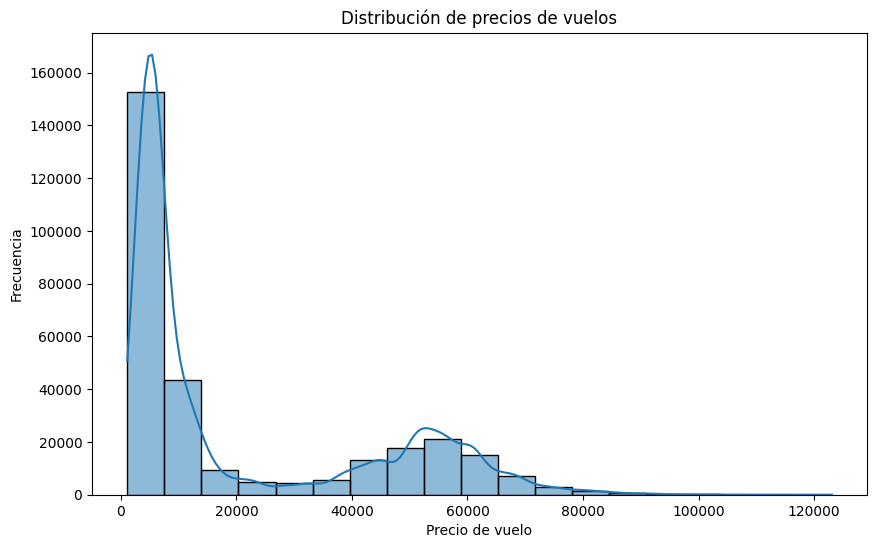

In [28]:
plt.figure(figsize=(10,6))
sns.histplot(df['price'], kde=True, bins=19)
plt.title('Distribución de precios de vuelos')
plt.xlabel('Precio de vuelo')
plt.ylabel('Frecuencia')
plt.show()

Maldita sea, es una distribución bimodal. Es posible que la razón de que este dataset sea bimodal es porque realmente hay dos poblaciones dependiendo de una característica: **La clase**

In [25]:
df_economy = df[df['class'] == 'Economy']
df_business = df[df['class'] != 'Economy']
df_business.shape

(93487, 10)

In [24]:
df_economy.shape

(206666, 10)

Para la clase economy:
$$k=1 + \log_{2}(206666) = 18.656941535 \approx 19$$
Para la clase business:
$$k=1 + \log_{2}(93487) = 17.512478142 \approx 18$$

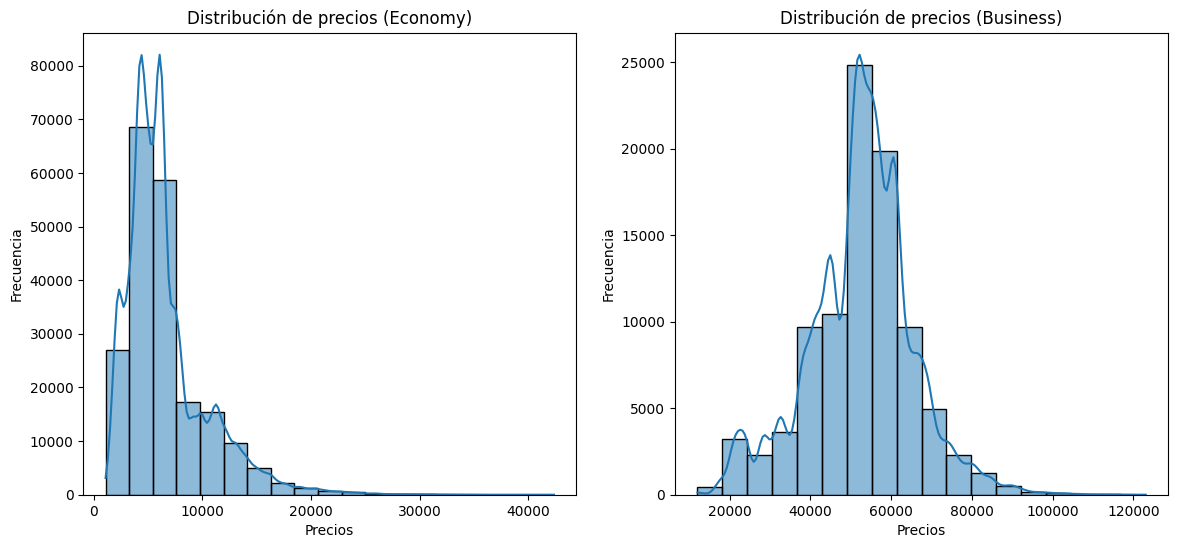

In [27]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(df_economy['price'], kde=True, bins=19)
plt.title("Distribución de precios (Economy)")
plt.xlabel("Precios")
plt.ylabel("Frecuencia")

plt.subplot(1, 2, 2)
sns.histplot(df_business['price'], kde=True, bins=18)
plt.title("Distribución de precios (Business)")
plt.xlabel("Precios")
plt.ylabel("Frecuencia")
plt.show()